In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
import itertools

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("combined.csv")
df.columns.tolist()
df.head()

,scenario,capture_split,capture_file,capture_start_utc,interval_start_utc,minute_from_capture_start,interval_start_seconds,packet_count,total_bytes,tcp_packets,udp_packets,icmp_packets,other_packets,ip_packets,unique_transport_ports
0,1-u4,test,botnet/1-u4/u4_test.pcapng,2025-01-14T20:24:26.119846+00:00,2025-01-14T20:24:26.119846+00:00,0,0,4,269,4,0,0,0,4,2
1,1-u4,test,botnet/1-u4/u4_test.pcapng,2025-01-14T20:24:26.119846+00:00,2025-01-14T20:25:26.119846+00:00,1,60,4,269,4,0,0,0,4,2
2,1-u4,test,botnet/1-u4/u4_test.pcapng,2025-01-14T20:24:26.119846+00:00,2025-01-14T20:26:26.119846+00:00,2,120,4,269,4,0,0,0,4,2
3,1-u4,test,botnet/1-u4/u4_test.pcapng,2025-01-14T20:24:26.119846+00:00,2025-01-14T20:27:26.119846+00:00,3,180,4,269,4,0,0,0,4,2
4,1-u4,test,botnet/1-u4/u4_test.pcapng,2025-01-14T20:24:26.119846+00:00,2025-01-14T20:28:26.119846+00:00,4,240,4,269,4,0,0,0,4,2


In [3]:
scenario_selected = "7-u6_3"
scenario_df = df[df["scenario"] == scenario_selected].copy()
print(scenario_df["capture_split"].value_counts())
print(
    scenario_df[
        ["capture_split", "capture_file", "capture_start_utc"]
    ].drop_duplicates().to_string(index=False)
)

capture_split
train    736
test     491
Name: count, dtype: int64
capture_split                    capture_file                capture_start_utc
         test  botnet/7-u6_3/u6_3-test.pcapng 2025-01-26T03:38:55.156708+00:00
        train botnet/7-u6_3/u6_3-train.pcapng 2025-01-25T15:23:16.578024+00:00


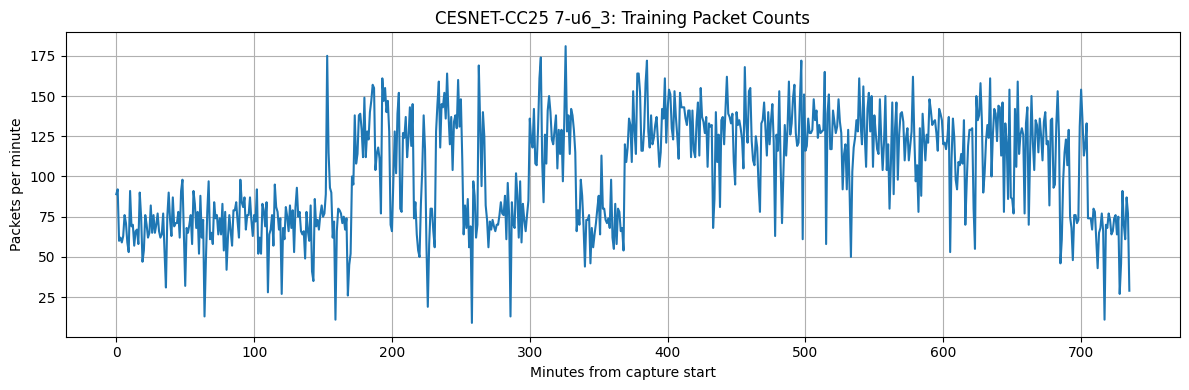

In [4]:
#Plotting the traning traffic

train_df = scenario_df[
    scenario_df["capture_split"] == "train"
].copy()

train_df = train_df.sort_values("minute_from_capture_start")

plt.figure(figsize=(12, 4))
plt.plot(
    train_df["minute_from_capture_start"],
    train_df["packet_count"]
)

plt.title(f"CESNET-CC25 {scenario_selected}: Training Packet Counts")
plt.xlabel("Minutes from capture start")
plt.ylabel("Packets per minute")
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
train_df = train_df.sort_values("minute_from_capture_start").copy()
train_df["block"] = (train_df["minute_from_capture_start"] // 100)
block_stats = train_df.groupby("block")["packet_count"].agg(["count", "mean", "std", "min", "max"])

print(block_stats.round(2))

       count    mean    std  min  max
block                                
0        100   69.87  14.26   13   98
1        100   86.82  33.46   11  175
2        100   95.72  35.17    9  169
3        100  109.83  32.73   44  181
4        100  127.83  21.87   61  172
5        100  124.62  20.26   50  165
6        100  113.90  27.15   46  161
7         36   74.61  28.56   11  154


In [ ]:
#Testing for stationarity using ADF
y = train_df["packet_count"].astype(float)
adf_result = adfuller(y, autolag="AIC")

print("ADF statistic: ", adf_result[0])
print("p-value: ", adf_result[1])
print("Lags used:", adf_result[2])
print("Observations used:", adf_result[3])
print("\nCritical values:")
for level, value in adf_result[4].items():
    print(f"{level}: {value:.4f}")

ADF statistic:  -3.72294489627491
p-value:  0.003801747879306597
Lags used: 8
Observations used: 727

Critical values:
1%: -3.4394
5%: -2.8655
10%: -2.5689


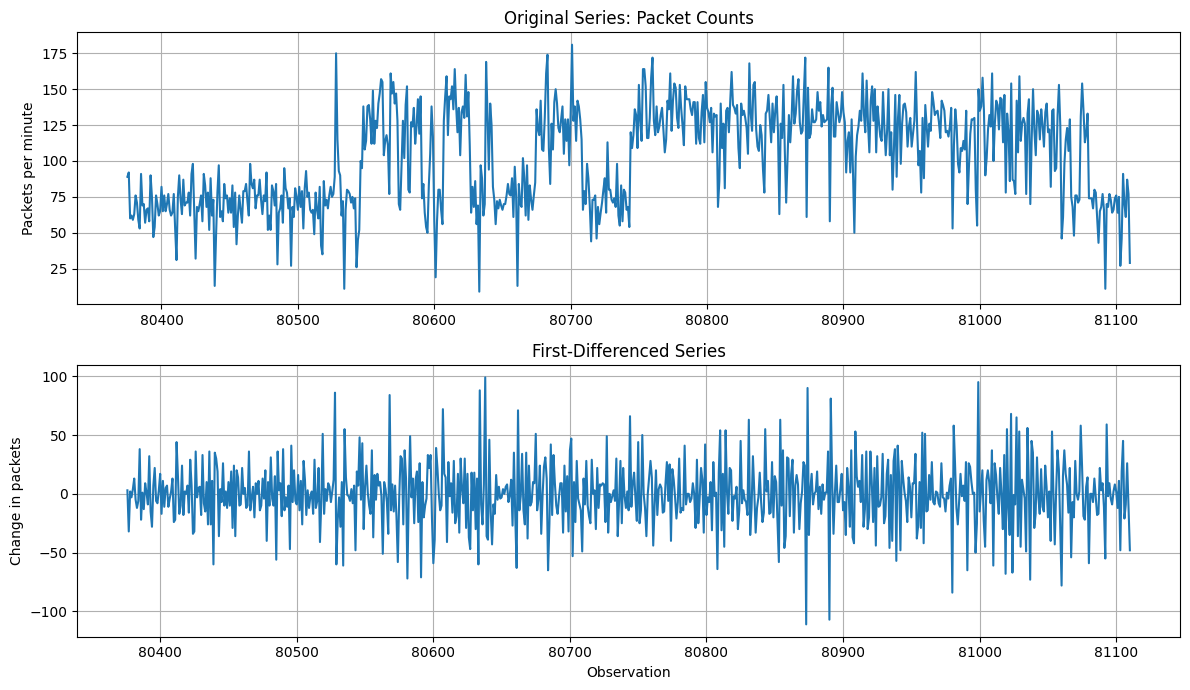

In [ ]:
y = train_df["packet_count"].astype(float)
y_diff = y.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(y)
axes[0].set_title("Original Series: Packet Counts")
axes[0].set_ylabel("Packets per minute")
axes[0].grid(True)
axes[1].plot(y_diff)
axes[1].set_title("First-Differenced Series")
axes[1].set_ylabel("Change in packets")
axes[1].set_xlabel("Observation")
axes[1].grid(True)
plt.tight_layout()
plt.show()

From above we can see the comparsion between a before and after it is important to consider that ARIMA is not great when the temporal landscape of the time series data is complex so by differencing we get a more stable pattern which can be seen with the comparsion plot above. 

In [8]:
adf_difference = adfuller(y_diff, autolag="AIC")
print("Original series p-value:", round(adf_result[1], 6))
print("Differenced series ADF statistic:", round(adf_difference[0], 4))
print("Differenced series p-value:", round(adf_difference[1], 6))
print("Lags used:", adf_difference[2])

Original series p-value: 0.003802
Differenced series ADF statistic: -12.4988
Differenced series p-value: 0.0
Lags used: 9


In [9]:
#Splitting training and tesing

y = (
    train_df
    .sort_values("minute_from_capture_start")["packet_count"]
    .astype(float)
    .reset_index(drop=True)
)

split_point = int(len(y) * 0.8)

y_train = y.iloc[:split_point]
y_val = y.iloc[split_point:]

print("Total observations:", len(y))
print("Model-fitting observations:", len(y_train))
print("Validation observations:", len(y_val))
print("Training range:", 0, "to", len(y_train) - 1)
print(
    "Validation range:",
    len(y_train),
    "to",
    len(y) - 1
)

Total observations: 736
Model-fitting observations: 588
Validation observations: 148
Training range: 0 to 587
Validation range: 588 to 735


In [10]:
p = range(4)
d = range(2)
q = range(4)
pdq_grid = list(itertools.product(p,d,q))
print("Candidates: ", pdq_grid)

Candidates:  [(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3), (1, 0, 0), (1, 0, 1), (1, 0, 2), (1, 0, 3), (1, 1, 0), (1, 1, 1), (1, 1, 2), (1, 1, 3), (2, 0, 0), (2, 0, 1), (2, 0, 2), (2, 0, 3), (2, 1, 0), (2, 1, 1), (2, 1, 2), (2, 1, 3), (3, 0, 0), (3, 0, 1), (3, 0, 2), (3, 0, 3), (3, 1, 0), (3, 1, 1), (3, 1, 2), (3, 1, 3)]


In [ ]:
#Fit candidates and evaluate forecasts
from sklearn.metrics import mean_absolute_error, mean_squared_error
results = []
for order in pdq_grid:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = ARIMA(y_train, order=order, enforce_stationarity=False, enforce_invertibility=False).fit()
            predictions = fitted.forecast(steps=len(y_val))
            mae = mean_absolute_error(y_val, predictions)
            rmse = np.sqrt(mean_squared_error(y_val, predictions))
            results.append({"order": order, "AIC": fitted.aic, "MAE": mae, "RMSE": rmse, "status": "ok"})
    except Exception as e:
        results.append({
            "order": order,
            "AIC": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
            "status": str(e)[:100]
        })
grid_results = pd.DataFrame(results)
grid_results = grid_results.sort_values(["RMSE", "MAE"], na_position="last").reset_index(drop=True)
print(grid_results.head(10).to_string(index=False))

    order         AIC       MAE      RMSE status
(2, 0, 1) 5350.536829 27.180909 31.250095     ok
(3, 0, 2) 5344.381040 27.233806 31.291450     ok
(1, 0, 3) 5334.348132 27.253822 31.306196     ok
(2, 0, 3) 5336.135008 27.252247 31.307510     ok
(2, 0, 2) 5342.460036 27.266902 31.316804     ok
(3, 0, 1) 5342.715528 27.276565 31.323459     ok
(3, 0, 3) 5338.069166 27.224429 31.339636     ok
(1, 0, 2) 5340.374373 27.109170 31.399998     ok
(1, 0, 1) 5354.867741 27.469513 31.483501     ok
(3, 0, 0) 5360.977709 27.914242 31.825116     ok


In [ ]:
valid_results = grid_results[
    (grid_results["status"] == "ok")
    & grid_results["RMSE"].notna()
]

best_row = valid_results.iloc[0]
best_order = best_row["order"]
print("Best order by validation RMSE:", best_order)
print("Validation RMSE:", round(best_row["RMSE"], 4))
print("Validation MAE:", round(best_row["MAE"], 4))
print("AIC:", round(best_row["AIC"], 2))

Best order by validation RMSE: (2, 0, 1)
Validation RMSE: 31.2501
Validation MAE: 27.1809
AIC: 5350.54


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

naive_predictions = np.repeat(y_train.iloc[-1], len(y_val))
naive_mae = mean_absolute_error(y_val, naive_predictions)
naive_rmse = np.sqrt(mean_squared_error(y_val, naive_predictions))

best_model = ARIMA(
    y_train,
    order=(2, 0, 1),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

arima_predictions = best_model.forecast(steps=len(y_val))
arima_mae = mean_absolute_error(y_val, arima_predictions)
arima_rmse = np.sqrt(mean_squared_error(y_val, arima_predictions))
print(f"Naive MAE:  {naive_mae:.3f}")
print(f"ARIMA MAE:  {arima_mae:.3f}")
print(f"Naive RMSE: {naive_rmse:.3f}")
print(f"ARIMA RMSE: {arima_rmse:.3f}")

print(
    "RMSE improvement (%):",
    round(100 * (naive_rmse - arima_rmse) / naive_rmse, 2)
)


Naive MAE:  27.486
ARIMA MAE:  27.181
Naive RMSE: 32.407
ARIMA RMSE: 31.250
RMSE improvement (%): 3.57


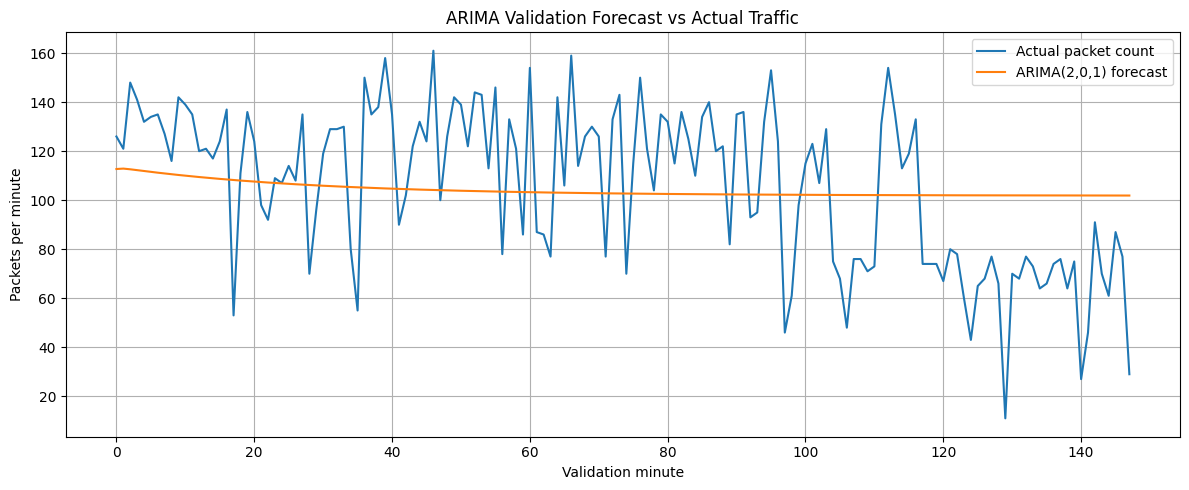

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot( y_val.reset_index(drop=True).to_numpy(),label="Actual packet count")
plt.plot(np.asarray(arima_predictions),label="ARIMA(2,0,1) forecast")
plt.title("ARIMA Validation Forecast vs Actual Traffic")
plt.xlabel("Validation minute")
plt.ylabel("Packets per minute")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:
actual = y_val.reset_index(drop=True).to_numpy()
predicted = np.asarray(arima_predictions)
residuals = actual - predicted

print("Mean residual:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))
print("95th percentile of absolute residuals:",
      round(np.quantile(np.abs(residuals), 0.95), 3))


Mean residual: 1.788
Residual standard deviation: 31.199
95th percentile of absolute residuals: 55.685


# Rolling Forecast #
Previous forecast was fixed-origin, so it couldn't adapt to the changing traffic level. In a live detector, we receive each new observation and predict the next minute.

In [16]:
rolling_model = ARIMA(y_train,order=(2, 0, 1),enforce_stationarity=False,enforce_invertibility=False).fit()

rolling_predictions = []
for actual_value in y_val:
    prediction = float(rolling_model.forecast(steps=1).iloc[0])
    rolling_predictions.append(prediction)
    rolling_model = rolling_model.append(
        [float(actual_value)],
        refit=False
    )

rolling_predictions = np.array(rolling_predictions)
actual = y_val.to_numpy()
rolling_mae = mean_absolute_error(actual, rolling_predictions)
rolling_rmse = np.sqrt(mean_squared_error(actual, rolling_predictions))
print("Rolling MAE:", round(rolling_mae, 3))
print("Rolling RMSE:", round(rolling_rmse, 3))


Rolling MAE: 19.399
Rolling RMSE: 25.562


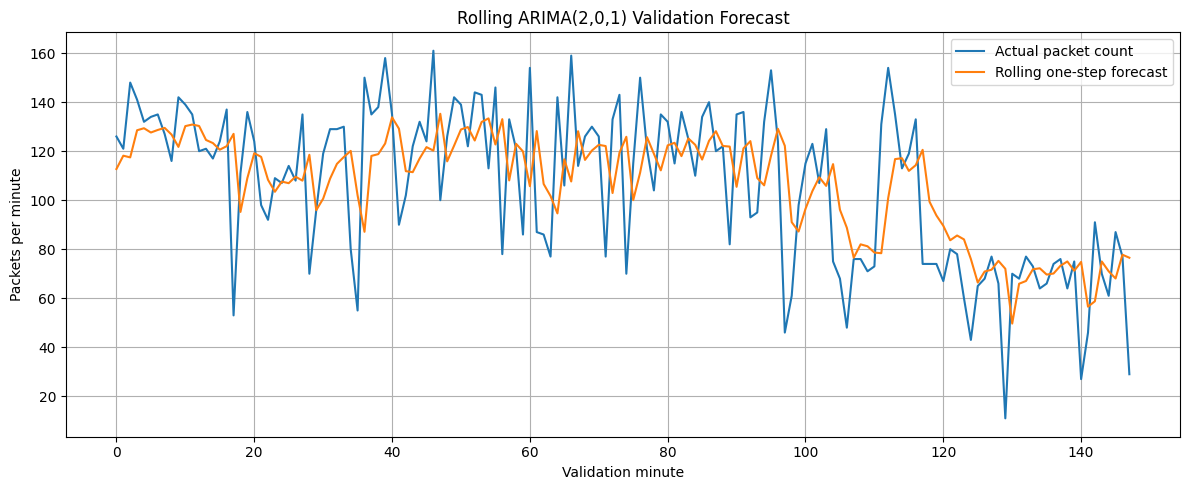

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual packet count")
plt.plot(
    rolling_predictions,
    label="Rolling one-step forecast"
)
plt.title("Rolling ARIMA(2,0,1) Validation Forecast")
plt.xlabel("Validation minute")
plt.ylabel("Packets per minute")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Rolling ARIMA metrics
rolling_mae = mean_absolute_error(actual, rolling_predictions)
rolling_rmse = np.sqrt(mean_squared_error(actual, rolling_predictions))
naive_rolling_predictions = y_val.shift(1).to_numpy().copy()
naive_rolling_predictions[0] = y_train.iloc[-1]
naive_rolling_mae = mean_absolute_error(
    actual, naive_rolling_predictions
)
naive_rolling_rmse = np.sqrt(
    mean_squared_error(actual, naive_rolling_predictions)
)

print(f"Rolling ARIMA MAE:  {rolling_mae:.3f}")
print(f"Rolling ARIMA RMSE: {rolling_rmse:.3f}")
print(f"Naive MAE:          {naive_rolling_mae:.3f}")
print(f"Naive RMSE:         {naive_rolling_rmse:.3f}")


Rolling ARIMA MAE:  19.399
Rolling ARIMA RMSE: 25.562
Naive MAE:          22.709
Naive RMSE:         30.776


In [19]:

# Divide the original training capture into fit and calibration segments.
cal_split = int(len(y) * 0.60)

y_fit = y.iloc[:cal_split]
y_cal = y.iloc[cal_split:split_point]

print("Model-fit observations:", len(y_fit))
print("Calibration observations:", len(y_cal))
print("Validation observations:", len(y_val))


Model-fit observations: 441
Calibration observations: 147
Validation observations: 148


In [20]:
cal_model = ARIMA(y_fit,order=(2, 0, 1),enforce_stationarity=False,enforce_invertibility=False).fit()
cal_predictions = []
for actual_value in y_cal:
    prediction = float(cal_model.forecast(steps=1).iloc[0])
    cal_predictions.append(prediction)

    cal_model = cal_model.append(
        [float(actual_value)],
        refit=False
    )

cal_predictions = np.asarray(cal_predictions)
cal_actual = y_cal.to_numpy()
cal_residuals = cal_actual - cal_predictions

print("Calibration observations:", len(cal_residuals))
print("Mean residual:", round(cal_residuals.mean(), 3))
print("Residual standard deviation:", round(cal_residuals.std(), 3))
print(
    "95th percentile of absolute residuals:",
    round(np.quantile(np.abs(cal_residuals), 0.95), 3)
)


Calibration observations: 147
Mean residual: 3.591
Residual standard deviation: 24.192
95th percentile of absolute residuals: 42.116


In [21]:
threshold_95 = np.quantile(np.abs(cal_residuals), 0.95)
threshold_99 = np.quantile(np.abs(cal_residuals), 0.99)

print(f"95th-percentile threshold: {threshold_95:.3f}")
print(f"99th-percentile threshold: {threshold_99:.3f}")
print("Calibration alerts at 95th percentile:",int((np.abs(cal_residuals) > threshold_95).sum()))
print("Calibration alerts at 99th percentile:",int((np.abs(cal_residuals) > threshold_99).sum()))

95th-percentile threshold: 42.116
99th-percentile threshold: 72.836
Calibration alerts at 95th percentile: 8
Calibration alerts at 99th percentile: 2


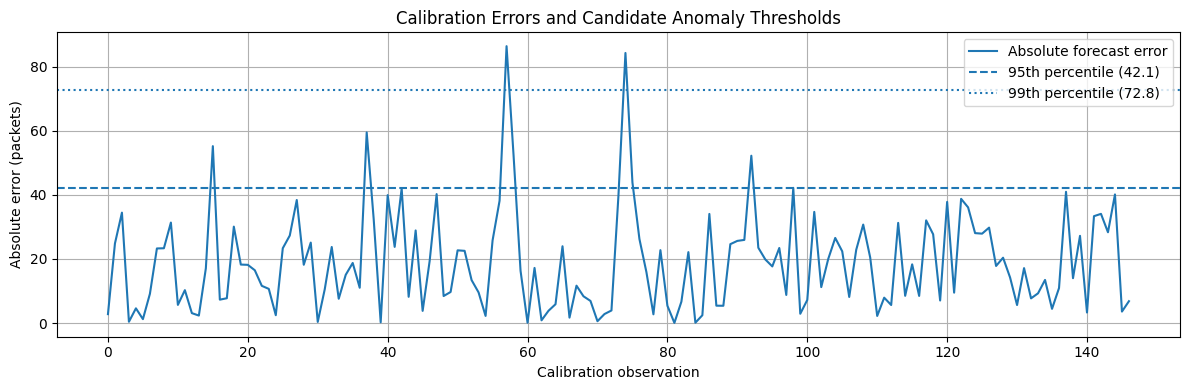

In [22]:
plt.figure(figsize=(12, 4))

plt.plot(np.abs(cal_residuals), label="Absolute forecast error")
plt.axhline(
    threshold_95,
    linestyle="--",
    label=f"95th percentile ({threshold_95:.1f})"
)
plt.axhline(
    threshold_99,
    linestyle=":",
    label=f"99th percentile ({threshold_99:.1f})"
)

plt.title("Calibration Errors and Candidate Anomaly Thresholds")
plt.xlabel("Calibration observation")
plt.ylabel("Absolute error (packets)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Validation observations: 148
Alerts at 95th-percentile threshold: 17
Alerts at 99th-percentile threshold: 2
95th-threshold alert rate: 11.49%
99th-threshold alert rate: 1.35%


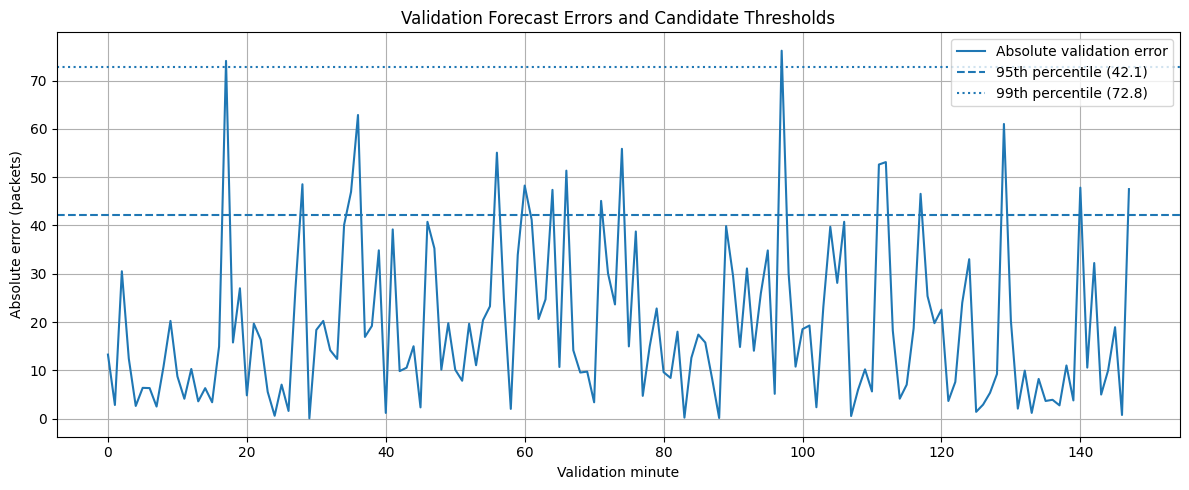

In [23]:
# Validation residuals from the rolling one-step-ahead forecast
validation_residuals = actual - rolling_predictions
abs_validation_residuals = np.abs(validation_residuals)
validation_alerts_95 = abs_validation_residuals > threshold_95
validation_alerts_99 = abs_validation_residuals > threshold_99

print("Validation observations:", len(actual))
print("Alerts at 95th-percentile threshold:",int(validation_alerts_95.sum()))
print("Alerts at 99th-percentile threshold:",int(validation_alerts_99.sum()))
print("95th-threshold alert rate:",f"{validation_alerts_95.mean() * 100:.2f}%")
print("99th-threshold alert rate:",f"{validation_alerts_99.mean() * 100:.2f}%")


plt.figure(figsize=(12, 5))
plt.plot(abs_validation_residuals,label="Absolute validation error")
plt.axhline(threshold_95,linestyle="--",label=f"95th percentile ({threshold_95:.1f})")
plt.axhline(threshold_99,linestyle=":",label=f"99th percentile ({threshold_99:.1f})")
plt.title("Validation Forecast Errors and Candidate Thresholds")
plt.xlabel("Validation minute")
plt.ylabel("Absolute error (packets)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Test observations: 491
Test capture files: <ArrowStringArray>
['botnet/7-u6_3/u6_3-test.pcapng']
Length: 1, dtype: str
Capture start times: <ArrowStringArray>
['2025-01-26T03:38:55.156708+00:00']
Length: 1, dtype: str

Packet-count summary:
count    491.000000
mean      93.203666
std       34.266770
min        6.000000
25%       68.000000
50%       82.000000
75%      123.500000
max      193.000000
Name: packet_count, dtype: float64


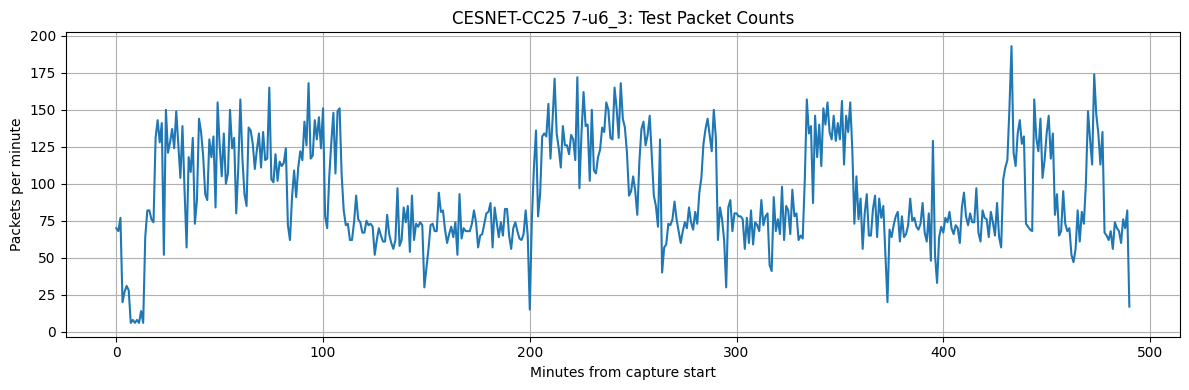

In [25]:

test_df = scenario_df[
    scenario_df["capture_split"] == "test"
].copy()

test_df = test_df.sort_values("minute_from_capture_start")

print("Test observations:", len(test_df))
print("Test capture files:", test_df["capture_file"].unique())
print(
    "Capture start times:",
    test_df["capture_start_utc"].unique()
)

print("\nPacket-count summary:")
print(test_df["packet_count"].describe())

plt.figure(figsize=(12, 4))
plt.plot(
    test_df["minute_from_capture_start"],
    test_df["packet_count"]
)
plt.title(f"CESNET-CC25 {scenario_selected}: Test Packet Counts")
plt.xlabel("Minutes from capture start")
plt.ylabel("Packets per minute")
plt.grid(True)
plt.tight_layout()
plt.show()


In [26]:

print("Training capture start:")
print(train_df["capture_start_utc"].iloc[0])
print("\nTraining capture last interval:")
print(train_df["interval_start_utc"].iloc[-1])
print("\nTest capture start:")
print(test_df["capture_start_utc"].iloc[0])
print("\nTraining rows:", len(train_df))
print("Test rows:", len(test_df))


Training capture start:
2025-01-25T15:23:16.578024+00:00

Training capture last interval:
2025-01-26T03:38:16.578024+00:00

Test capture start:
2025-01-26T03:38:55.156708+00:00

Training rows: 736
Test rows: 491


In [27]:

final_model = ARIMA(
    y,
    order=(2, 0, 1),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

test_predictions = []
for actual_value in test_df["packet_count"].astype(float):
    prediction = float(final_model.forecast(steps=1).iloc[0])
    test_predictions.append(prediction)

    final_model = final_model.append(
        [float(actual_value)],
        refit=False
    )

test_predictions = np.asarray(test_predictions)
test_actual = test_df["packet_count"].to_numpy()

test_residuals = test_actual - test_predictions

print("Test MAE:", round(
    np.mean(np.abs(test_residuals)), 3
))
print("Test RMSE:", round(
    np.sqrt(np.mean(test_residuals ** 2)), 3
))


Test MAE: 17.593
Test RMSE: 23.301


In [28]:
test_abs_errors = np.abs(test_residuals)
test_alerts_95 = test_abs_errors > threshold_95
test_alerts_99 = test_abs_errors > threshold_99

print("Test observations:", len(test_actual))

print(
    "Alerts at 95th-percentile threshold:",
    int(test_alerts_95.sum()),
    f"({test_alerts_95.mean() * 100:.2f}%)"
)

print(
    "Alerts at 99th-percentile threshold:",
    int(test_alerts_99.sum()),
    f"({test_alerts_99.mean() * 100:.2f}%)"
)


Test observations: 491
Alerts at 95th-percentile threshold: 42 (8.55%)
Alerts at 99th-percentile threshold: 2 (0.41%)


In [29]:

test_results = test_df[
    [
        "scenario",
        "minute_from_capture_start",
        "interval_start_utc",
        "packet_count"
    ]
].reset_index(drop=True).copy()

test_results["predicted_packet_count"] = test_predictions
test_results["residual"] = test_residuals
test_results["absolute_error"] = np.abs(test_residuals)

test_results["alert_95"] = test_results["absolute_error"] > threshold_95
test_results["alert_99"] = test_results["absolute_error"] > threshold_99

print("Alerts at 95th percentile:")
print(
    test_results.loc[
        test_results["alert_95"],
        [
            "minute_from_capture_start",
            "packet_count",
            "predicted_packet_count",
            "residual",
            "absolute_error"
        ]
    ].to_string(index=False)
)

print("\nAlerts at 99th percentile:")
print(
    test_results.loc[
        test_results["alert_99"],
        [
            "minute_from_capture_start",
            "packet_count",
            "predicted_packet_count",
            "residual",
            "absolute_error"
        ]
    ].to_string(index=False)
)


Alerts at 95th percentile:
 minute_from_capture_start  packet_count  predicted_packet_count   residual  absolute_error
                         3            20               73.433675 -53.433675       53.433675
                        14            64               21.838034  42.161966       42.161966
                        19           131               66.240080  64.759920       64.759920
                        20           143               90.308636  52.691364       52.691364
                        23            52              114.087954 -62.087954       62.087954
                        24           150               84.933130  65.066870       65.066870
                        34            57              111.602811 -54.602811       54.602811
                        38            73              116.371435 -43.371435       43.371435
                        40           144               98.434223  45.565777       45.565777
                        49           155             

In [30]:

test_results["positive_alert_95"] = (
    test_results["residual"] > threshold_95
)

test_results["negative_alert_95"] = (
    test_results["residual"] < -threshold_95
)

test_results["positive_alert_99"] = (
    test_results["residual"] > threshold_99
)

test_results["negative_alert_99"] = (
    test_results["residual"] < -threshold_99
)

print("95th-percentile threshold")
print(
    "Positive alerts:",
    int(test_results["positive_alert_95"].sum())
)
print(
    "Negative alerts:",
    int(test_results["negative_alert_95"].sum())
)

print("\n99th-percentile threshold")
print(
    "Positive alerts:",
    int(test_results["positive_alert_99"].sum())
)
print(
    "Negative alerts:",
    int(test_results["negative_alert_99"].sum())
)


95th-percentile threshold
Positive alerts: 21
Negative alerts: 21

99th-percentile threshold
Positive alerts: 1
Negative alerts: 1
